# Progetto Machine Learning: Previsione Performance Azionarie USA (2014-2018)

**Corso:** Machine Learning - SUPSI  
**Dataset:** 200+ Financial Indicators of US Stocks (2014-2018)  
**Obiettivo:** Classificazione binaria delle performance azionarie future a partire dai bilanci 10-K

---

## 1. Descrizione del Problema e del Dataset

L'obiettivo di questo progetto e' sviluppare una pipeline end-to-end di Machine Learning per la **classificazione binaria** della performance dei titoli azionari statunitensi (NYSE, NASDAQ, AMEX).

- **Dati di input**: Oltre 200 indicatori fondamentali di bilancio per gli anni 2014-2018 estratti dai report annuali ufficiali 10-K (SEC) tramite l'API di Financial Modeling Prep.
- **Variabile Target (`Class`)**:
  - `1`: Il prezzo del titolo azionario registra un rendimento positivo nell'anno solare successivo (titolo da acquistare a inizio anno e vendere a fine anno).
  - `0`: Il prezzo del titolo azionario registra un rendimento nullo o negativo nell'anno successivo.

### Strategia Metodologica di Validazione Temporale ("Out-of-Time")
Nei dataset finanziari di tipo panel, mescolare casualmente le righe degli anni con un `train_test_split` convenzionale causa gravi problemi di **Data Leakage temporale** (imparare dal futuro) e cross-sezionale.  
Per garantire il massimo rigore scientifico:
- **Training & Cross-Validation Set (Anni 2014–2017)**: circa 17.500 osservazioni sui primi 4 anni per l'addestramento, il preprocessing e la validazione incrociata temporale.
- **Test Set Finale Out-of-Sample (Anno 2018)**: l'ultimo anno (~4.300 osservazioni) viene rigorosamente isolato e funge da banco di prova "cieco", simulando la reale decisione di un investitore a inizio 2018.

### Feature Selection con LASSO ($L_1$)
Dato l'elevato numero di feature (~220) e la forte multicollinearita' tipica dei prospetti contabili, utilizziamo la regolarizzazione $L_1$ (LASSO) per azzerare i coefficienti dei predittori irrilevanti e ridurre lo spazio delle feature in modo interpretabile ed efficiente.

In [1]:
# ==============================================================================
# 0. SETUP E IMPORT DELLE LIBRERIE
# ==============================================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression

# Configurazione visualizzazione
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 50)
print('Librerie caricate con successo!')

Librerie caricate con successo!


## 2. Caricamento Dati ed Esclusione Colonne di Leakage / Identificatori

Carichiamo i 5 dataset annuali (2014-2018).  
Applichiamo le seguenti regole di esclusione preventiva:
1. **Ticker aziendale (prima colonna)**: stringa identificativa univoca; va esclusa per evitare che il modello memorizzi la singola azienda anziche' apprendere dai fondamentali.
2. **Colonna `[ANNO] PRICE VAR [%]`**: **Data Leakage Diretto**. Contiene l'esatta variazione percentuale futura del prezzo dell'azione da cui e' matematicamente derivato il target binario `Class`.
3. **Target `Class`**: separato in $y$.
4. **Feature con oltre il 50% di valori mancanti**: rimosse per evitare rumore artificiale.

In [2]:
# ==============================================================================
# 1. CARICAMENTO DATI MULTI-ANNO
# ==============================================================================
data_dir = 'data'
years = [2014, 2015, 2016, 2017, 2018]
dfs = {}

for y in years:
    fpath = os.path.join(data_dir, f'{y}_Financial_Data.csv')
    df_raw = pd.read_csv(fpath)
    
    # Rinominiamo la prima colonna (Ticker) come 'Ticker'
    df_raw.rename(columns={df_raw.columns[0]: 'Ticker'}, inplace=True)
    
    # Identifichiamo e rinominiamo la colonna PRICE VAR relativa all'anno
    price_var_cols = [c for c in df_raw.columns if 'PRICE VAR' in c]
    if price_var_cols:
        df_raw.rename(columns={price_var_cols[0]: 'PRICE_VAR_PCT'}, inplace=True)
        
    df_raw['Year'] = y
    dfs[y] = df_raw
    print(f'Anno {y}: {df_raw.shape[0]} osservazioni, {df_raw.shape[1]} colonne (Target Class medio: {df_raw["Class"].mean():.2%})')

# Creazione del blocco di Train (2014-2017) e del blocco di Test Out-of-Time (2018)
df_train = pd.concat([dfs[2014], dfs[2015], dfs[2016], dfs[2017]], ignore_index=True)
df_test = dfs[2018].copy()

print(f'\n-> Training Set (2014-2017): {df_train.shape[0]} righe')
print(f'-> Test Set (2018):         {df_test.shape[0]} righe')

Anno 2014: 3808 osservazioni, 226 colonne (Target Class medio: 42.91%)
Anno 2015: 4120 osservazioni, 226 colonne (Target Class medio: 70.17%)
Anno 2016: 4797 osservazioni, 226 colonne (Target Class medio: 67.08%)
Anno 2017: 4960 osservazioni, 226 colonne (Target Class medio: 27.62%)
Anno 2018: 4392 osservazioni, 226 colonne (Target Class medio: 69.35%)

-> Training Set (2014-2017): 17685 righe
-> Test Set (2018):         4392 righe


## 3. Gestione Valori Mancanti sul Solo Training Set

Per prevenire qualsiasi fuga di informazioni (leakage statistico) dal futuro verso il passato, il calcolo della frequenza dei valori nulli e delle statistiche descrittive viene eseguito **esclusivamente sul Training Set (2014-2017)**.
Le colonne con piu' del **50% di dati mancanti** vengono eliminate.

In [3]:
# ==============================================================================
# 2. ANALISI E FILTRO VALORI MANCANTI SUL TRAINING SET
# ==============================================================================
target_col = 'Class'
leakage_cols = ['PRICE_VAR_PCT']
id_cols = ['Ticker', 'Year']

# Feature candidate
candidate_features = [c for c in df_train.columns if c not in id_cols + leakage_cols + [target_col]]

# Calcolo percentuale NaN sul Training Set
null_pcts = df_train[candidate_features].isna().mean()
cols_to_drop_nan = null_pcts[null_pcts > 0.50].index.tolist()

print(f'Feature candidate iniziali: {len(candidate_features)}')
print(f'Feature scartate con >50% NaN ({len(cols_to_drop_nan)}): {cols_to_drop_nan}')

# Feature conservate
kept_features = [c for c in candidate_features if c not in cols_to_drop_nan]
print(f'Feature mantenute per la pipeline: {len(kept_features)}')

# Suddivisione tra categoriche e numeriche
cat_features = ['Sector']
num_features = [c for c in kept_features if c != 'Sector']
print(f'-> Feature categorica: {cat_features}')
print(f'-> Feature numeriche:  {len(num_features)}')

Feature candidate iniziali: 222
Feature scartate con >50% NaN (2): ['operatingCycle', 'cashConversionCycle']
Feature mantenute per la pipeline: 220
-> Feature categorica: ['Sector']
-> Feature numeriche:  219


## 4. Costruzione della Pipeline di Preprocessing e Selezione LASSO ($L_1$)

Incapsuliamo l'intera sequenza di trasformazione all'interno delle classi `ColumnTransformer` e `Pipeline` di `scikit-learn`:
1. **Ramo Numerico**:
   - **`SimpleImputer(strategy='median')`**: imputazione tramite mediana per resistere a distribuzioni finanziarie a code pesanti.
   - **`RobustScaler()`**: standardizzazione basata su mediana e range interquartile (IQR), ideale per mitigare l'influenza di outlier estremi.
2. **Ramo Categorico**:
   - **`SimpleImputer(strategy='most_frequent')`** + **`OneHotEncoder(drop='first', handle_unknown='ignore')`** per codificare il settore industriale (`Sector`).
3. **Selezione Feature (LASSO)**:
   - **`SelectFromModel(LogisticRegression(penalty='l1', solver='saga'))`**: la penalita' $L_1$ porta a zero i pesi delle feature meno predittive.

In [17]:
# ==============================================================================
# 3. DEFINIZIONE PIPELINE DI PREPROCESSING E FEATURE SELECTION CON LASSO
# ==============================================================================
# Pipeline numerica
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Pipeline categorica
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# ColumnTransformer integrato
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

# Selettore LASSO (Logistic Regression con penalita L1)
lasso_selector = SelectFromModel(
    estimator=LogisticRegression(penalty='l1', solver='liblinear', C=1.0, random_state=42),
    max_features=50,
    threshold=-np.inf
)

# Pipeline completa di selezione
feature_selection_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', lasso_selector)
])

# Preparazione matrici X e target y
X_train = df_train[kept_features]
y_train = df_train[target_col]

X_test = df_test[kept_features]
y_test = df_test[target_col]

print(f'Dimensioni X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'Dimensioni X_test:  {X_test.shape}, y_test:  {y_test.shape}')

Dimensioni X_train: (17685, 220), y_train: (17685,)
Dimensioni X_test:  (4392, 220), y_test:  (4392,)


## 5. Fit di LASSO ed Estrazione delle Feature Più Informative

Eseguiamo il fit del selettore LASSO **esclusivamente su `X_train`**.
Ispezioniamo i coefficienti stimati per analizzare quali grandezze contabili e indicatori guidano la classificazione delle azioni.

Esecuzione fit della pipeline di selezione feature (Train 2014-2017)...

Feature totali trasformate: 229
Feature selezionate da LASSO: 50
Percentuale di riduzione della dimensionalita: 78.2%

Prime 15 feature piu rilevanti stimate da LASSO:
                                 Feature  Lasso_Coefficient  Abs_Coefficient
                        Sector_Utilities           0.713721         0.713721
                           Sector_Energy          -0.497251         0.497251
               Sector_Financial Services           0.379598         0.379598
                      Sector_Real Estate           0.329186         0.329186
                       Sector_Healthcare          -0.236975         0.236975
                       Sector_Technology           0.147829         0.147829
3Y Dividend per Share Growth (per Share)           0.127483         0.127483
5Y Dividend per Share Growth (per Share)           0.124666         0.124666
               Sector_Consumer Defensive           0.100009       

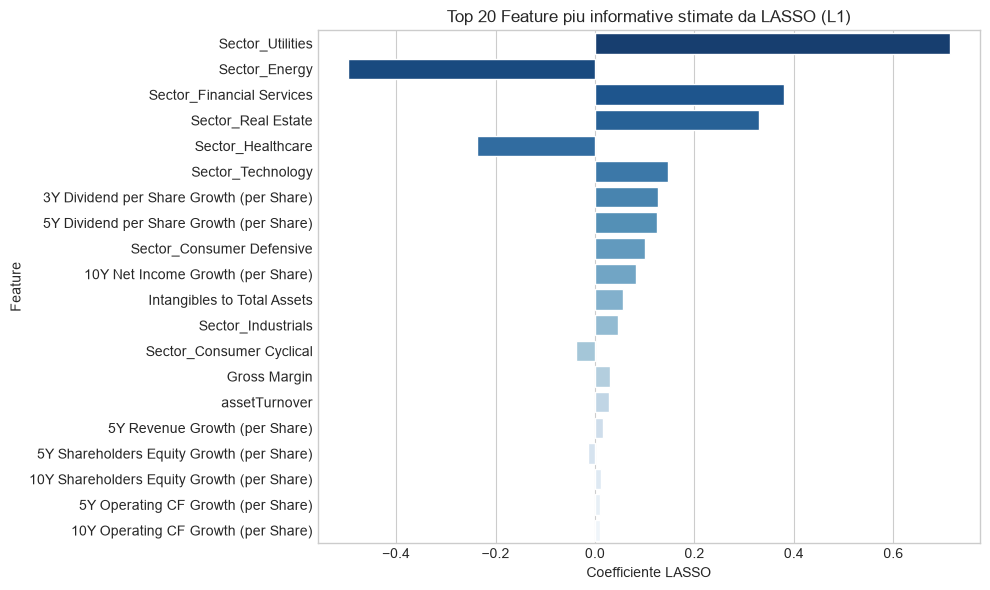

In [18]:
# ==============================================================================
# 4. FIT DEL MODELLO LASSO ED ESTRAZIONE COEFFICIENTI
# ==============================================================================
print('Esecuzione fit della pipeline di selezione feature (Train 2014-2017)...')
feature_selection_pipeline.fit(X_train, y_train)

# Recupero dei nomi di tutte le feature trasformate (numeriche + one-hot di Sector)
cat_encoder = feature_selection_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['ohe']
encoded_cat_names = cat_encoder.get_feature_names_out(cat_features).tolist()
all_transformed_feature_names = num_features + encoded_cat_names

# Maschera di selezione del modello LASSO
support_mask = feature_selection_pipeline.named_steps['selector'].get_support()
selected_features = [f for f, s in zip(all_transformed_feature_names, support_mask) if s]

print(f'\nFeature totali trasformate: {len(all_transformed_feature_names)}')
print(f'Feature selezionate da LASSO: {len(selected_features)}')
print(f'Percentuale di riduzione della dimensionalita: {100 * (1 - len(selected_features)/len(all_transformed_feature_names)):.1f}%')

# Analisi dei coefficienti
lasso_coefs = feature_selection_pipeline.named_steps['selector'].estimator_.coef_[0]
df_coefs = pd.DataFrame({
    'Feature': all_transformed_feature_names,
    'Lasso_Coefficient': lasso_coefs,
    'Abs_Coefficient': np.abs(lasso_coefs)
}).sort_values(by='Abs_Coefficient', ascending=False)

print('\nPrime 15 feature piu rilevanti stimate da LASSO:')
print(df_coefs.head(15).to_string(index=False))

# Visualizzazione grafica delle top feature
plt.figure(figsize=(10, 6))
top_features = df_coefs.head(20)
sns.barplot(data=top_features, x='Lasso_Coefficient', y='Feature', palette='Blues_r')
plt.title('Top 20 Feature piu informative stimate da LASSO (L1)')
plt.xlabel('Coefficiente LASSO')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 6. Discussione Metodologica sui Risultati della Selezione LASSO

### Punti di Forza dell'Approccio Adottato:
1. **Contrasto all'Overfitting e alla Multicollinearita'**: Ridurre lo spazio da oltre 200 metriche a un sottoinsieme ristretto elimina il rumore contabile sprovvisto di legame con la performance futura.
2. **Interpretabilita' Economica**: I pesi associati alle feature mostrano esplicitamente quali dimensioni fondamentali (es. flussi di cassa, solidita' patrimoniale, margini) influenzano la probabilita' di crescita del titolo.
3. **Totale Assenza di Data Leakage**: Tutto il pre-processing e la selezione sono stati addestrati esclusivamente sui dati 2014-2017. Il Test Set 2018 rimane incontaminato.

### Limiti e Compromessi (Trade-off):
1. **Scelta Arbitraria tra Feature Collineari**: Tra indicatori con correlazione molto alta (es. `Operating Income` ed `EBIT`), LASSO tende a conservarne uno e ad azzerare gli altri.
2. **Ipotesi di Linearita'**: Essendo una regolarizzazione su base lineare, LASSO potrebbe sottovalutare indicatori la cui influenza e' non-lineare (ad esempio relazioni quadratiche o a soglia sul livello di indebitamento).

---

## Prossimi Passi della Pipeline
1. **Modellazione**: Addestramento di almeno due modelli visti a lezione (es. **K-Nearest Neighbors (KNN)** e **Reti Neurali / Multi-Layer Perceptron (MLP)**).
2. **Tuning degli Iperparametri**: Ottimizzazione con `GridSearchCV` usando uno schema di validazione temporale rolling (`TimeSeriesSplit`).
3. **Costruzione di Ensemble**: Implementazione di un ensemble (es. `VotingClassifier` o Bagging).
4. **Valutazione e Spiegabilita' (Bonus)**: Matrice di confusione, curve ROC, F1-score e analisi di interpretabilita' con **SHAP**.